# Stock 2: few rows, many clues, and a strange test row

For stock 2 the hard part is not making a prediction. It's knowing **how wrong the prediction might be**.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data and find the traps |
| 3 | Compare many models fairly (GridSearchCV) |
| 4 | Find the clues that really matter |
| 5 | Predict stock 2 and see the data with our line |
| 6 | Measure how sure we are |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data, `x1` to `x100`. A measurement that might help predict the price. |
| **Row** | One example: one set of 100 clue values and its price. |
| **Weight** | How much the price changes when a clue goes up by 1. |
| **std** (standard deviation) | The typical distance of values from their average. We use it as a "ruler". |
| **CV RMSE** | How many pounds the model is wrong by, on average, on rows it hasn't seen. Smaller is better. |
| **Extrapolate** | Predict for values outside the range the model learned from. Risky. |

Run the cells from top to bottom (or **Restart**, then **Run All**).

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

In [38]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, RepeatedKFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

pd.set_option("display.max_colwidth", None)    # show long text in tables in full, without "..."
print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

In [39]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_2_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_2_test.csv")     # the one row we must price

clue_columns = [c for c in train.columns if c.startswith("x")]   # x1 ... x100

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", len(clue_columns))
train.head()

Training data: 140 rows
Test data:     1 row
Clues:         100


,uid,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x92,x93,x94,x95,x96,x97,x98,x99,x100,price
0,54d5c4f6b6,-0.4724,-0.6009,-0.9965,-1.3729,-0.1462,-1.1286,-0.3447,-0.3928,-1.1060,...,-0.2043,0.7353,1.1949,0.0663,-0.2057,0.2122,-0.4268,0.0800,-0.4551,63.75
1,a379494ba8,0.7236,0.8112,1.2548,0.7265,0.8826,0.5650,0.1632,0.5795,1.1818,...,1.0181,1.7100,0.6866,0.1154,1.0552,1.7650,0.1573,0.5091,1.6204,83.43
2,9c14027187,0.4003,-0.6817,-0.9378,0.4076,-1.1492,-0.0512,-1.5468,-1.2420,-2.0109,...,0.4967,0.5469,-0.0070,0.8200,-0.6151,0.9660,0.4406,-0.0698,0.3614,79.19
3,7744811a70,1.0100,1.0358,1.3612,2.8049,1.5654,2.0095,1.7116,2.6077,2.7689,...,1.1178,0.6260,0.2710,1.3623,-0.0084,1.1163,1.8620,0.0329,-0.3431,88.08
4,f2b8c158d3,-0.8718,-1.5394,-0.6881,-1.3195,-0.4958,-1.0809,-1.4366,-2.2070,-0.3582,...,0.9159,-0.7728,-0.2877,1.1784,0.4611,0.1471,0.7287,0.6913,0.5638,88.98


**Only 140 rows, but 100 clues.** Stock 1 had 20,000 rows and 6 clues.

With so few examples and so many clues, a model can easily "find" patterns that are just luck. Imagine trying to work out which of 100 ingredients makes a cake taste good from only 140 cakes: some ingredients will look important purely by chance.

### Step 1.3: Quick health check

We look for empty cells and repeated rows. We want zeros.

In [40]:
print("Empty cells in train:", train.isna().sum().sum())
print("Empty cells in test: ", test.isna().sum().sum())
print("Repeated rows in train:", train[clue_columns].duplicated().sum())
train["price"].describe().round(2)

Empty cells in train: 0
Empty cells in test:  0
Repeated rows in train: 0


count    140.00
mean      76.34
std       13.95
min       40.77
25%       68.31
50%       75.76
75%       85.96
max      125.50
Name: price, dtype: float64

No empty cells and no repeated rows. Prices average about **£76**, and most are within about £14 of that.

> **✅ Checkpoint.** The data are clean, but small: 140 rows, 100 clues.

---
# Part 2: Look at the data

### Step 2.1: Is the test row "normal"?

A model only knows what it has seen. Think of heights: if you've only ever seen people between 150 cm and 195 cm, and someone walks in at 240 cm, any guess about them is risky.

So we ask two simple questions about the test row:

1. **Is it outside the range?** For each clue: is the test value bigger than the biggest training value, or smaller than the smallest?
2. **How far out is it?** For each clue, we measure the distance from the training average, counted in std "steps". Then we average over all 100 clues.

To know what "far" means, we compare with the training rows themselves.

In [41]:
test_row = test[clue_columns].iloc[0]          # the test row: 100 numbers, one per clue
train_mean = train[clue_columns].mean()        # average of each clue in training
train_std = train[clue_columns].std()          # std of each clue in training

# Question 1: how many clues are outside the training range?
outside = (test_row > train[clue_columns].max()) | (test_row < train[clue_columns].min())
print("Clues where the test value is outside the training range:", outside.sum(), "out of", len(clue_columns))

# Question 2: how far from the average, in std steps?
z_test = (test_row - train_mean) / train_std                  # distance of each test value, in std steps
z_train = (train[clue_columns] - train_mean) / train_std      # the same for every training value

print(f"Typical training value: {z_train.abs().mean().mean():.1f} std steps from the average")
print(f"Typical test value:     {z_test.abs().mean():.1f} std steps from the average")

Clues where the test value is outside the training range: 100 out of 100
Typical training value: 0.8 std steps from the average
Typical test value:     3.2 std steps from the average


**How to read this**

* **All 100 clues** of the test row are outside the training range.
* A typical training value is about **0.8 std steps** from the average. That's normal for bell-shaped data: most values sit close to the average, a few are far, and the average distance comes out at about 0.8.
* A typical test value is about **3.2 std steps** away, roughly **4 times further** than normal, on every clue.

The pictures below show the same thing. On the left, every row gets one "how unusual is it" score. On the right are the 4 most important clues (we find out why they matter in Part 4).

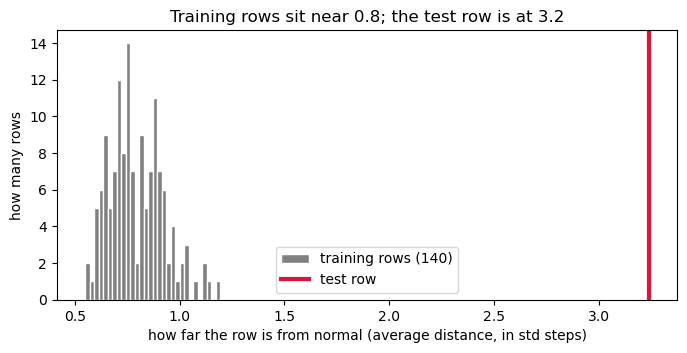

In [42]:
row_score_train = z_train.abs().mean(axis=1)     # one "how unusual" score per training row
row_score_test = z_test.abs().mean()             # the same score for the test row

plt.figure(figsize=(8, 3.5))
plt.hist(row_score_train, bins=30, color="grey", edgecolor="white", label="training rows (140)")
plt.axvline(row_score_test, color="crimson", linewidth=3, label="test row")
plt.xlabel("how far the row is from normal (average distance, in std steps)")
plt.ylabel("how many rows")
plt.title(f"Training rows sit near 0.8; the test row is at {row_score_test:.1f}")
plt.legend()
plt.show()

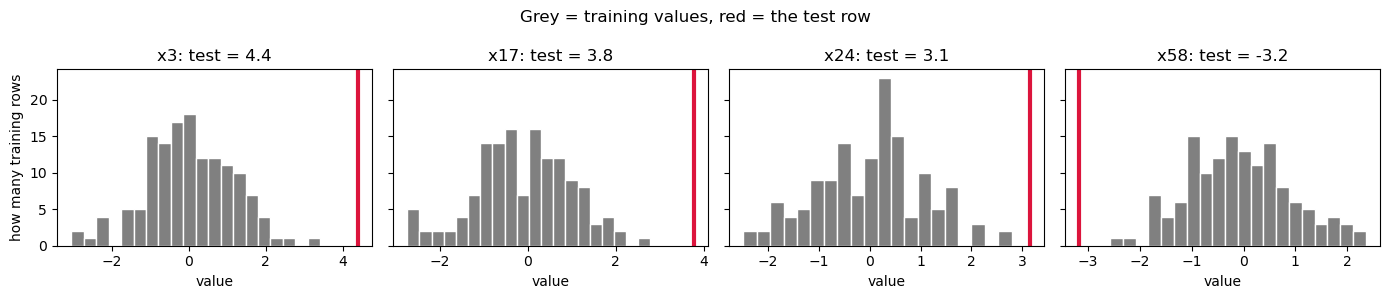

In [43]:
key_clues = ["x3", "x17", "x24", "x58"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, clue in zip(axes, key_clues):
    ax.hist(train[clue], bins=20, color="grey", edgecolor="white")    # training values
    ax.axvline(test_row[clue], color="crimson", linewidth=3)          # test value
    ax.set_title(f"{clue}: test = {test_row[clue]:.1f}")
    ax.set_xlabel("value")
axes[0].set_ylabel("how many training rows")
fig.suptitle("Grey = training values, red = the test row")
plt.tight_layout()
plt.show()

The red line sits at the edge of the grey bars or beyond them. The model has never seen values like these, so it has to **extrapolate**. The guide warns about exactly this: *"If the test row is unusual, your real error can be much bigger than your validation error suggests."*

### Step 2.2: Do the clues move together?

**Why we check this.** Think of houses: "size in m²" and "number of rooms" move together, because big houses have more rooms. If both go up with price, the data alone can't tell you which one really causes it. For normal houses that doesn't matter. But for a strange house (huge, with only 1 room), a model that trusts size and a model that trusts rooms give very different prices.

**Correlation** measures how much two clues move together: **+1** = always up together, **−1** = one goes up when the other goes down, **0** = unrelated.

Below, every square is one pair of clues, coloured by their correlation.

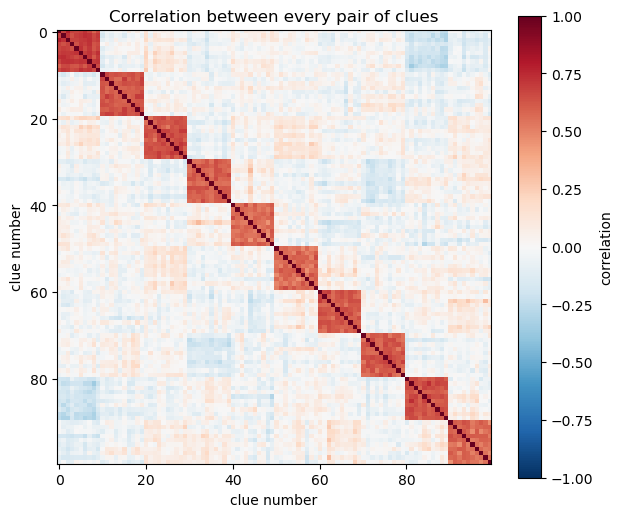

In [44]:
corr = train[clue_columns].corr()     # correlation of every clue with every other clue

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.title("Correlation between every pair of clues")
plt.xlabel("clue number"); plt.ylabel("clue number")
plt.show()

The clues come in **10 groups of 10**: `x1–x10`, `x11–x20`, …, `x91–x100`. Inside a group the clues move together strongly (the dark squares on the diagonal). Different groups are unrelated.

Think of each group as **10 thermometers in the same room**: they all show roughly the same temperature.

### Step 2.3: Which groups matter for the price?

In [45]:
groups = [[f"x{i}" for i in range(start, start + 10)] for start in range(1, 101, 10)]
corr_with_price = train[clue_columns].corrwith(train["price"])     # each clue's correlation with price

rows = []
for g in groups:
    inside = corr.loc[g, g].values[np.triu_indices(10, 1)]         # every pair of clues inside the group
    best = corr_with_price[g].abs().idxmax()                       # the clue most related to price
    rows.append({
        "group": f"{g[0]}–{g[-1]}",
        "move together (avg corr)": round(inside.mean(), 2),
        "typical corr with price": round(corr_with_price[g].median(), 2),
        "strongest clue": best,
        "its corr with price": round(corr_with_price[best], 2),
    })
pd.DataFrame(rows)

,group,move together (avg corr),typical corr with price,strongest clue,its corr with price
0,x1–x10,0.69,0.42,x3,0.64
1,x11–x20,0.63,-0.36,x17,-0.46
2,x21–x30,0.64,0.30,x24,0.42
3,x31–x40,0.60,-0.04,x35,-0.12
4,x41–x50,0.56,-0.02,x43,-0.14
5,x51–x60,0.56,0.24,x58,0.38
6,x61–x70,0.61,-0.09,x68,-0.18
7,x71–x80,0.61,-0.08,x72,-0.21
8,x81–x90,0.63,0.09,x84,0.11
9,x91–x100,0.56,-0.00,x92,0.07


**How to read the columns**

| Column | Meaning |
|---|---|
| move together | How strongly the 10 clues in the group move together. All groups are about 0.6–0.7, so strongly. |
| typical corr with price | How related a typical clue in the group is to price. Near 0 = this group doesn't matter. |
| strongest clue | The clue in the group most related to price. |
| its corr with price | How strongly that clue is related to price. |

**What it tells us**

* Four groups matter: `x1–x10`, `x11–x20` (price goes **down** when these go up), `x21–x30` and `x51–x60`. The other six are mostly noise.
* In group `x1–x10`, **x3** has 0.64 while the others are only around 0.42. That's the sign that **x3 is the real driver**. The others only *look* related to price because they move together with x3, like followers copying the leader. The same goes for **x17**, **x24** and **x58** in their groups.

### Step 2.4: The trap

In training, the clues inside a group move together. Let's look at the test row inside group `x1–x10`, and compare **x3** with **the average of the whole group** (add up `x1`…`x10` and divide by 10).

In [46]:
group_1 = groups[0]                                     # x1 ... x10
group_1_average = train[group_1].mean(axis=1)           # the group average for every training row

print(f"Training: correlation between x3 and the group-1 average = {train['x3'].corr(group_1_average):.2f}")
print("          (they move together very strongly)\n")

print("Test row, group x1–x10:")
print(test_row[group_1].round(2).to_string())
print(f"\nTest row: x3 = {test_row['x3']:.2f}, but the group-1 average = {test_row[group_1].mean():.2f}")

Training: correlation between x3 and the group-1 average = 0.87
          (they move together very strongly)

Test row, group x1–x10:
x1     3.38
x2     3.20
x3     4.38
x4    -4.06
x5     4.22
x6    -3.41
x7    -3.78
x8    -3.68
x9     4.29
x10   -4.24

Test row: x3 = 4.38, but the group-1 average = 0.03


**What this means**

* In training, x3 and the group average move together very strongly (correlation 0.87). So a model that uses **x3** and a model that uses **the group average** look equally good on the training data.
* In the test row, half the group is about **+4** and half is about **−4**. They cancel out, so the group average is about **0**, while x3 is **+4.4**.
* With a weight of about £7.7 per unit, the "x3 model" adds about **+£34** to the price, and the "group-average model" adds about **£0**.

One choice that looks harmless in training changes the prediction by **about £34**. That's why we need to know which clue is the real driver.

> **✅ Checkpoint.** Stock 2 has three traps: (1) few rows, many clues; (2) clues that move together in groups; (3) a test row far outside the training data that also breaks the group pattern.

---
# Part 3: Compare models fairly

### Step 3.1: The fair-test setup

With only 140 rows, one 80/20 split is too dependent on luck. Instead we use **repeated K-fold cross-validation**:

1. Cut the data into **5 parts**.
2. Train on 4 parts and test on the 5th. Do this 5 times, so every part is tested once.
3. Repeat everything **5 times** with different random cuts, and average all **25** scores.

In [47]:
X = train[clue_columns]          # the clues
y = train["price"]               # the answers
X_test = test[clue_columns]      # the test row's clues

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)   # 5 parts × 5 repeats = 25 fair tests

### Step 3.2: Scaling inside a Pipeline

Every model goes inside a **Pipeline**: first `StandardScaler`, then the model.

**What the scaler does:** it puts every clue on the same scale (average 0, std 1), so no clue looks "bigger" just because of its units.

**Is it OK to scale the test row?** Yes, and it's necessary. There are two different things:

| | What it means | OK? |
|---|---|---|
| **Learn** the scaling from the test row | Calculate the average and std from the test data | ❌ Information leaks from the test data |
| **Apply** the training scaling to the test row | Rescale the test row using the training average and std | ✅ Required |

The model learns on scaled numbers, so it must also receive scaled numbers. It's like heights: if a model learns in metres, you can't give it a test height in centimetres. The Pipeline does this correctly by itself: it learns the scaling from the training data only, and applies the same scaling to the test row when we call `predict`.

### Step 3.3: The models and their settings

**Group A, checked with GridSearchCV** (tries every combination of settings):

| Model | Setting | What it controls |
|---|---|---|
| Linear regression | (none) | Plain straight line using all 100 clues. |
| Ridge | `alpha` | How hard all weights are shrunk towards 0. |
| Lasso | `alpha` | How hard weights are pushed to **exactly 0** (bigger = fewer clues kept). |
| ElasticNet | `alpha`, `l1_ratio` | A mix of Ridge and Lasso. |
| PLS | `n_components` | How many combined clues to build. |
| Random forest | `min_samples_leaf` | Smallest group of rows allowed at the end of a tree branch. |
| Gradient boosting | `max_depth`, `learning_rate` | Tree size and learning speed. |

In [48]:
grid_models = {
    "Linear regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-2, 4, 25)}),
    "Lasso": (Lasso(max_iter=50000), {"model__alpha": np.logspace(-2, 1, 25)}),
    "ElasticNet": (ElasticNet(max_iter=50000), {"model__alpha": np.logspace(-2, 1, 15),
                                                "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "PLS": (PLSRegression(), {"model__n_components": [1, 2, 3, 5, 8, 10]}),
    "Random forest": (RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=1),
                      {"model__min_samples_leaf": [1, 3, 10]}),
    "Gradient boosting": (HistGradientBoostingRegressor(random_state=0),
                          {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1]}),
}
print("Group A models:", list(grid_models.keys()))

Group A models: ['Linear regression', 'Ridge', 'Lasso', 'ElasticNet', 'PLS', 'Random forest', 'Gradient boosting']


**Group B, XGBoost and LightGBM, checked with RandomizedSearchCV.**

These two have many useful settings. Trying every combination would mean hundreds of combinations × 25 tests, which is too slow. `RandomizedSearchCV` works the same way as GridSearchCV, but tries **40 random combinations** instead of all of them, which usually finds a setting just as good.

| Setting | What it controls | Why it helps with 140 rows |
|---|---|---|
| `n_estimators` | How many trees | More trees learn more, but can memorise noise |
| `learning_rate` | How big a correction each new tree makes | Smaller = more careful learning |
| `max_depth` / `num_leaves` | How big each tree can grow | Small trees can't memorise 140 rows |
| `min_child_weight` / `min_child_samples` | Fewest rows allowed at the end of a branch | Stops branches built on 1–2 rows (usually noise) |
| `subsample` | Share of rows each tree sees | A bit of randomness reduces memorising |
| `colsample_bytree` | Share of clues each tree sees | Helps when most clues are noise |
| `reg_alpha` | Penalty that pushes useless clues' effect to 0 (like Lasso) | Most of our 100 clues are useless |
| `reg_lambda` | Penalty that keeps all effects small (like Ridge) | Makes the model calmer |

In [49]:
random_models = {
    "XGBoost": (XGBRegressor(random_state=0, n_jobs=1),        # n_jobs=1: the search already uses all cores
                {"model__n_estimators": [200, 400, 800],
                 "model__learning_rate": [0.02, 0.05, 0.1],
                 "model__max_depth": [2, 3, 4],
                 "model__min_child_weight": [1, 3, 5],
                 "model__subsample": [0.7, 0.85, 1.0],
                 "model__colsample_bytree": [0.3, 0.5, 1.0],
                 "model__reg_alpha": [0, 0.5, 2],
                 "model__reg_lambda": [1, 5, 10]}),
    "LightGBM": (LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1),  # subsample_freq=1 switches subsample on
                 {"model__n_estimators": [200, 400, 800],
                  "model__learning_rate": [0.02, 0.05, 0.1],
                  "model__num_leaves": [3, 4, 8],
                  "model__min_child_samples": [3, 5, 10],
                  "model__subsample": [0.7, 0.85, 1.0],
                  "model__colsample_bytree": [0.3, 0.5, 1.0],
                  "model__reg_alpha": [0, 0.5, 2],
                  "model__reg_lambda": [0, 5, 10]}),
}
print("Group B models:", list(random_models.keys()))

Group B models: ['XGBoost', 'LightGBM']


### Step 3.4: Run the contest

This takes a few minutes. For each model, the search tries the settings, keeps the best one, retrains it on all 140 rows, and prices the test row.

In [50]:
results = []
searches = {}

def record(name, search):
    # save one finished search and its results
    searches[name] = search
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 2),
        "test prediction (£)": round(float(np.ravel(search.predict(X_test))[0]), 2),
        "best settings": search.best_params_,
    })
    print(f"{name} done")

for name, (model, settings) in grid_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = GridSearchCV(pipe, settings, cv=cv,
                          scoring="neg_root_mean_squared_error",   # sklearn maximises, so RMSE is made negative
                          n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (model, settings) in random_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = RandomizedSearchCV(pipe, settings, n_iter=40, cv=cv, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results = pd.DataFrame(results).sort_values("CV RMSE (£)").reset_index(drop=True)
results

Linear regression done
Ridge done
Lasso done
ElasticNet done
PLS done
Random forest done
Gradient boosting done
XGBoost done
LightGBM done


,model,CV RMSE (£),test prediction (£),best settings
0,Lasso,4.82,88.56,{'model__alpha': 0.23713737056616552}
1,ElasticNet,5.07,82.18,"{'model__alpha': 0.19306977288832497, 'model__l1_ratio': 0.8}"
2,Ridge,6.25,82.97,{'model__alpha': 10.0}
3,PLS,6.44,94.62,{'model__n_components': 8}
4,LightGBM,7.26,74.54,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__num_leaves': 3, 'model__n_estimators': 800, 'model__min_child_samples': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.5}"
5,XGBoost,7.33,77.84,"{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__n_estimators': 400, 'model__min_child_weight': 5, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}"
6,Gradient boosting,7.62,78.61,"{'model__learning_rate': 0.1, 'model__max_depth': 3}"
7,Random forest,9.52,81.66,{'model__min_samples_leaf': 1}
8,Linear regression,13.02,65.65,{}


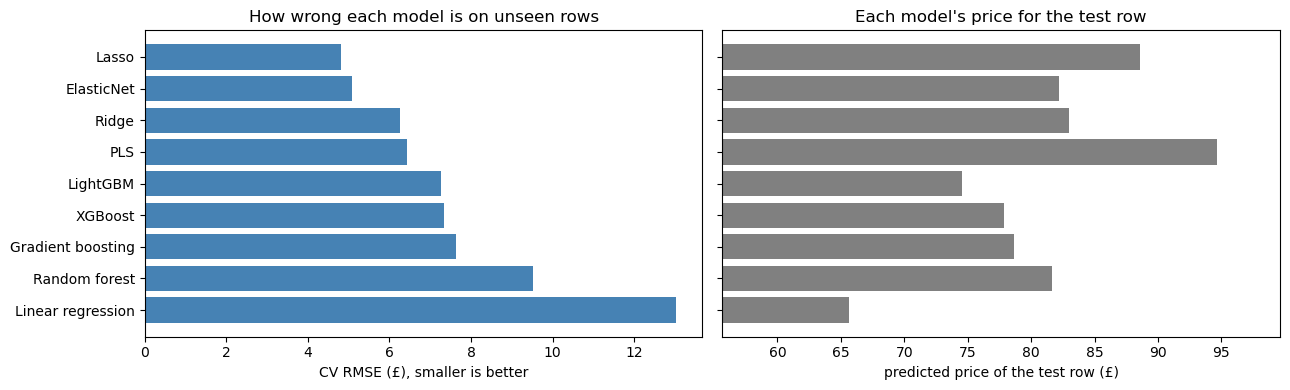

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

axes[0].barh(results["model"], results["CV RMSE (£)"], color="steelblue")
axes[0].set_xlabel("CV RMSE (£), smaller is better")
axes[0].set_title("How wrong each model is on unseen rows")
axes[0].invert_yaxis()                                        # best model at the top

axes[1].barh(results["model"], results["test prediction (£)"], color="grey")
axes[1].set_xlabel("predicted price of the test row (£)")
axes[1].set_title("Each model's price for the test row")
axes[1].set_xlim(results["test prediction (£)"].min() - 10, results["test prediction (£)"].max() + 5)

plt.tight_layout()
plt.show()

**What this shows**

* **Lasso and ElasticNet win** (about £5). They keep only a handful of clues and throw the rest away, which is exactly what this data needs.
* **Plain linear regression is the worst** (about £13). With 100 clues and only 140 rows, it memorises noise.
* **Tree models (random forest, gradient boosting, XGBoost, LightGBM) are in the middle** (about £7–9.5). The extra settings helped XGBoost and LightGBM a little (from about £7.5 to £7.3), but not enough. A tree can never predict outside the range of prices it has seen, so it can't extrapolate to an extreme test row.

Now look at the right-hand chart: the models disagree by **more than £20** on the same row. That's the first warning that this test row is risky.

> **✅ Checkpoint.** The best family is **sparse linear models** (Lasso). But different models give very different prices for this test row.

---
# Part 4: Find the clues that matter

### Step 4.1: What did Lasso keep?

Lasso sets the weight of useless clues to exactly 0. Here are the clues that survived. (The weights are for the scaled clues, so their sizes can be compared fairly.)

In [52]:
best_lasso = searches["Lasso"].best_estimator_
lasso_alpha = searches["Lasso"].best_params_["model__alpha"]
lasso_weights = pd.Series(best_lasso.named_steps["model"].coef_, index=clue_columns)
kept = lasso_weights[lasso_weights != 0].sort_values(key=abs, ascending=False)

print(f"Lasso kept {len(kept)} clues out of 100. The 10 biggest weights:")
kept.head(10).round(2).to_frame("weight")

Lasso kept 38 clues out of 100. The 10 biggest weights:


,weight
x3,8.24
x17,-5.93
x24,3.95
x58,3.16
x71,-1.65
x90,0.94
x59,0.93
x83,0.83
x87,0.82
x36,0.80


**x3, x17, x24 and x58** have by far the biggest weights: the four leaders we spotted in Part 2. After them come smaller ones (x71, x90, x59, …), then a long tail of tiny weights.

### Step 4.2: Which clues are real, and which are luck?

With only 140 rows, Lasso might keep some clues by luck. To test this we use the **bootstrap**.

Think of football: to find the really good players you don't watch one match, because a weak player can get lucky once. You watch **200 matches**, and a really good player shines in almost all of them.

1. Make a slightly different dataset by picking 140 rows at random from the original. Some rows get picked twice, some not at all. That's one "match".
2. Run Lasso on it and note which clues it keeps.
3. Repeat **200 times** and count how often each clue was kept.

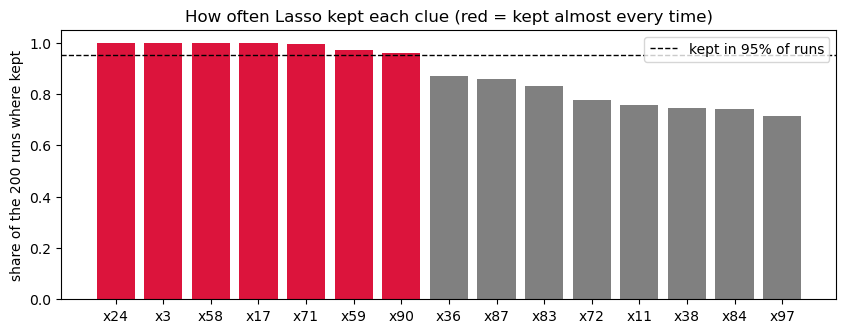

,share of runs where kept
x24,1.000
x3,1.000
x58,1.000
x17,1.000
x71,0.995
x59,0.970
x90,0.960
x36,0.870
x87,0.860
x83,0.830


In [53]:
rng = np.random.default_rng(0)
times_kept = pd.Series(0, index=clue_columns)

for b in range(200):
    rows = rng.integers(0, len(train), len(train))                 # 140 random rows, some picked twice
    pipe = Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=lasso_alpha, max_iter=50000))])
    pipe.fit(X.iloc[rows], y.iloc[rows])
    times_kept += (pipe.named_steps["model"].coef_ != 0)           # add 1 for every clue that was kept

kept_share = (times_kept / 200).sort_values(ascending=False)

plt.figure(figsize=(10, 3.5))
top = kept_share.head(15)
plt.bar(top.index, top.values, color=["crimson" if v >= 0.95 else "grey" for v in top.values])
plt.axhline(0.95, color="black", linestyle="--", linewidth=1, label="kept in 95% of runs")
plt.ylabel("share of the 200 runs where kept")
plt.title("How often Lasso kept each clue (red = kept almost every time)")
plt.legend()
plt.show()

kept_share.head(12).to_frame("share of runs where kept")

**How to read it**

| Clue | Share | Meaning |
|---|---|---|
| x3, x17, x24, x58 | 1.00 | Kept in all 200 runs, so definitely real |
| x71 | 0.995 | Kept in 199 of 200, so real |
| x59, x90 | 0.96–0.97 | Kept almost every time, so very likely real |
| x36, x87, x83 | 0.83–0.87 | Sometimes missing, so less sure |
| x72, x11 | about 0.75 | Often missing, so probably luck |

A clue that truly drives the price shows up whatever mix of rows we use. A clue that only looked useful by chance comes and goes.

### Step 4.3: Add the clues one by one

Now we build plain linear regressions with 1 clue, then 2, then 3, and so on.

**The order is "most important first"**, using the Lasso weights from Step 4.1 and the shares from Step 4.2: the four leaders (x3, x17, x24, x58), then the smaller ones (x71, x90, x59, x87). It's like picking a team: add the best players first, and stop when adding more stops helping. (x59 and x90 are almost tied, so their order doesn't matter.)

For each model we record two things: the **CV RMSE** (how good the model is) and its **price for the test row**.

In [54]:
order = ["x3", "x17", "x24", "x58", "x71", "x90", "x59", "x87"]

steps = []
for k in range(1, len(order) + 1):
    clues_k = order[:k]                                            # the first k clues in the list
    rmse_k = -cross_val_score(LinearRegression(), X[clues_k], y, cv=cv,
                              scoring="neg_root_mean_squared_error").mean()
    pred_k = LinearRegression().fit(X[clues_k], y).predict(X_test[clues_k])[0]
    steps.append({"number of clues": k, "clue added": clues_k[-1],
                  "CV RMSE (£)": round(rmse_k, 2), "test prediction (£)": round(pred_k, 2)})
steps = pd.DataFrame(steps)
steps

,number of clues,clue added,CV RMSE (£),test prediction (£)
0,1,x3,10.83,110.67
1,2,x17,8.51,87.49
2,3,x24,6.94,99.36
3,4,x58,5.40,84.47
4,5,x71,5.01,90.89
5,6,x90,4.49,101.72
6,7,x59,4.43,106.82
7,8,x87,4.36,110.26


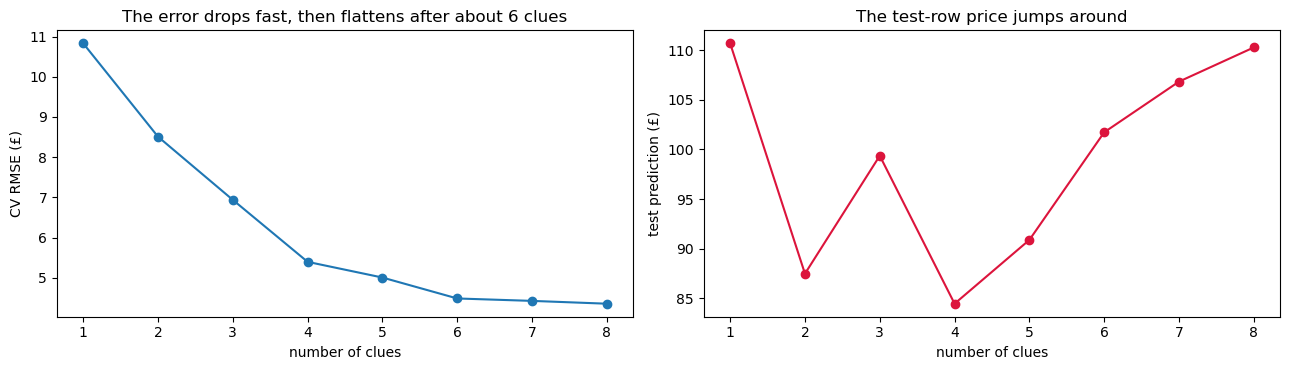

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].plot(steps["number of clues"], steps["CV RMSE (£)"], marker="o")
axes[0].set_xlabel("number of clues"); axes[0].set_ylabel("CV RMSE (£)")
axes[0].set_title("The error drops fast, then flattens after about 6 clues")

axes[1].plot(steps["number of clues"], steps["test prediction (£)"], marker="o", color="crimson")
axes[1].set_xlabel("number of clues"); axes[1].set_ylabel("test prediction (£)")
axes[1].set_title("The test-row price jumps around")

for ax in axes:
    ax.set_xticks(steps["number of clues"])
plt.tight_layout()
plt.show()

**Two lessons**

1. **Left:** the error falls quickly up to **6 clues** (£4.49), then hardly improves. So 6 clues is enough.
2. **Right:** the test-row price jumps by £10–20 every time we add a clue, even when the error barely changes. That's the extreme test row at work: its clues are about ±3 to ±4, so even a small weight of £2 gets multiplied into £6–8.

> **✅ Checkpoint.** The real drivers are **x3, x17, x24, x58**, plus the smaller **x71** and **x90**. Our main model is **linear regression on these 6 clues**. (x59 is borderline: it barely improves the error, so it's left out of the main model, but we use a 7-clue version as a second opinion in Part 7.)

---
# Part 5: Predict stock 2

### Step 5.1: Train the final model and predict

Lasso was the right tool for **finding** the clues. For the final model we use **plain linear regression on the 6 chosen clues**. Lasso shrinks every weight a little towards 0. On normal rows that hardly matters, but on our extreme test row those small shrinkages add up to several pounds.

In [56]:
final_clues = ["x3", "x17", "x24", "x58", "x71", "x90"]

final_model = LinearRegression()
final_model.fit(X[final_clues], y)                      # learn from all 140 rows

prediction = final_model.predict(X_test[final_clues])[0]
print(f"Predicted price of stock 2: £{prediction:.2f}")

Predicted price of stock 2: £101.72


### Step 5.2: No magic, just arithmetic

Same as notebook 1: **start + weight × value** for each clue.

**Where does the start come from?** It's the price the model predicts when **all clues are 0**. In our data every clue averages about 0, so "all clues = 0" is a perfectly average row, and the start (about £75) is close to the average price (£76). Linear regression calculates it together with the weights.

In [57]:
total = final_model.intercept_
print(f"start{'':24}{total:8.2f}")
for clue, weight in zip(final_clues, final_model.coef_):
    value = X_test[clue].iloc[0]
    total += weight * value
    print(f"+ {weight:6.2f} × {clue:3s} ({value:6.2f})   {weight * value:+8.2f}")
print(f"{'= prediction':29}{total:8.2f}")

start                           75.22
+   7.68 × x3  (  4.38)     +33.68
+  -6.15 × x17 (  3.78)     -23.21
+   4.92 × x24 (  3.15)     +15.51
+   4.03 × x58 ( -3.17)     -12.76
+  -2.43 × x71 ( -2.50)      +6.09
+   2.42 × x90 (  2.98)      +7.19
= prediction                   101.72


In stock 1 the pieces were a few pounds each. Here they are **£6 to £34** each, and they partly cancel each other out. A small mistake in any weight gets multiplied by 3–4, which is why this prediction is fragile.

### Step 5.3: See the data and our line, one clue at a time

With 6 clues we can't draw one simple line like in notebook 1, so we draw **one chart per clue**.

In each chart, the effect of the other 5 clues is **removed** from the price, so we see only this clue's effect.

* **Dots:** training rows
* **Red line:** our model's line for this clue (its slope is the weight)
* **Shaded area:** the range of values seen in training
* **Dashed line:** the test row's value

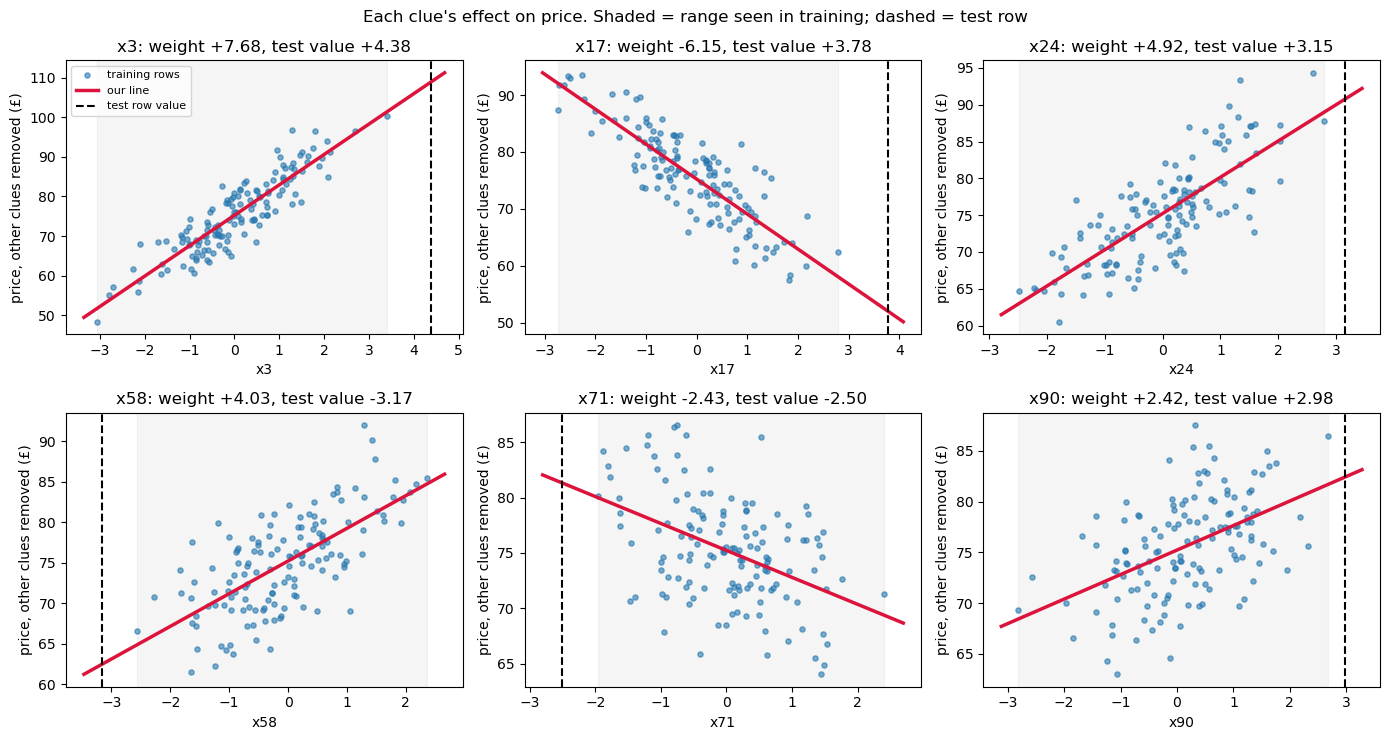

In [58]:
weights = dict(zip(final_clues, final_model.coef_))       # each clue's weight from the final model

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, clue in zip(axes.ravel(), final_clues):
    others = [c for c in final_clues if c != clue]
    effect_of_others = (X[others] * [weights[c] for c in others]).sum(axis=1)   # price change caused by the other 5 clues
    price_adjusted = y - effect_of_others                                         # price with the other clues' effect removed

    ax.scatter(X[clue], price_adjusted, s=14, alpha=0.6, label="training rows")

    test_value = X_test[clue].iloc[0]
    xs = np.linspace(min(X[clue].min(), test_value) - 0.3, max(X[clue].max(), test_value) + 0.3, 50)
    ax.plot(xs, final_model.intercept_ + weights[clue] * xs, color="crimson", linewidth=2.5, label="our line")

    ax.axvline(test_value, color="black", linestyle="--", linewidth=1.5, label="test row value")
    ax.axvspan(X[clue].min(), X[clue].max(), color="grey", alpha=0.08)        # shaded = range seen in training
    ax.set_title(f"{clue}: weight {weights[clue]:+.2f}, test value {test_value:+.2f}")
    ax.set_xlabel(clue); ax.set_ylabel("price, other clues removed (£)")

axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Each clue's effect on price. Shaded = range seen in training; dashed = test row")
plt.tight_layout()
plt.show()

**How to read it**

* The dots follow the red line closely, so each relationship really is a **straight line**.
* For **x3, x17, x24 and x58**, the dashed line is **outside the shaded area**. The model has to extend its line where it has no data. That's extrapolation.
* For x71 and x90 the test value sits right at the edge of the training data.

### Step 5.4: The whole model at once

Every training row is one dot: **what the model predicted** (across) against **the real price** (up). If the model were perfect, every dot would sit on the red diagonal.

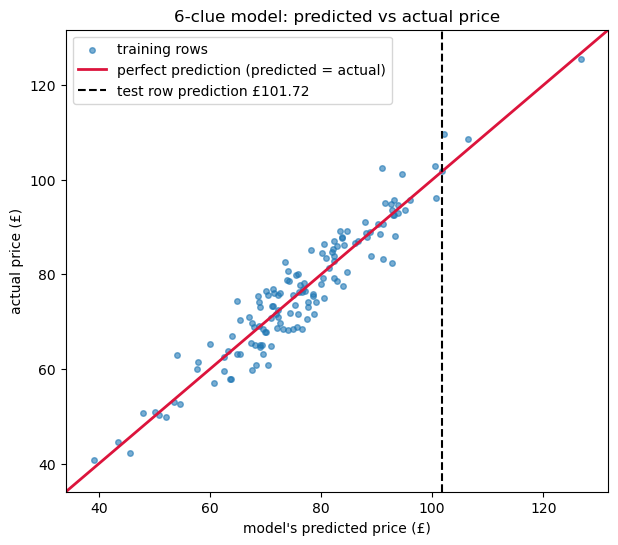

In [59]:
fitted = final_model.predict(X[final_clues])               # the model's prediction for every training row

plt.figure(figsize=(7, 6))
plt.scatter(fitted, y, s=16, alpha=0.6, label="training rows")
lims = [min(fitted.min(), y.min()) - 5, max(fitted.max(), y.max(), prediction) + 5]
plt.plot(lims, lims, color="crimson", linewidth=2, label="perfect prediction (predicted = actual)")
plt.axvline(prediction, color="black", linestyle="--", linewidth=1.5, label=f"test row prediction £{prediction:.2f}")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("model's predicted price (£)"); plt.ylabel("actual price (£)")
plt.title("6-clue model: predicted vs actual price")
plt.legend(loc="upper left")
plt.show()

**How to read it**

* The dots sit close to the diagonal, so on normal rows the model is accurate (about £4–5 off).
* The test row's prediction (dashed) lands among the higher training prices. The final number looks ordinary, but it's built from extreme clue values (Step 5.3), so it's less reliable than it looks.

> **✅ Checkpoint.** Our best single guess is about **£100**. The model fits the training data well, but the test row sits beyond the data on the 4 main clues.

---
# Part 6: How sure are we?

### Step 6.1: The CV RMSE is too optimistic here

The CV RMSE (about £4–5) measures errors on **normal** rows. Our test row is not normal. To measure the uncertainty for *this* row, we use the bootstrap again:

1. Pick 140 rows at random (some twice, some not at all).
2. Refit the model and price the test row.
3. Repeat 500 times and see how much the prices spread.

We do it for two models: our 6-clue linear regression, and the Lasso (which picks its own clues every time).

In [60]:
rng = np.random.default_rng(1)
boot_6clues, boot_lasso = [], []

for b in range(500):
    rows = rng.integers(0, len(train), len(train))
    Xb, yb = X.iloc[rows], y.iloc[rows]

    m6 = LinearRegression().fit(Xb[final_clues], yb)
    boot_6clues.append(m6.predict(X_test[final_clues])[0])

    ml = Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=lasso_alpha, max_iter=50000))])
    ml.fit(Xb, yb)
    boot_lasso.append(ml.predict(X_test)[0])

boot_6clues, boot_lasso = np.array(boot_6clues), np.array(boot_lasso)
for name, b in [("6-clue linear", boot_6clues), ("Lasso", boot_lasso)]:
    print(f"{name:14s} average £{b.mean():6.2f}   spread (std) £{b.std():5.2f}   "
          f"middle 90%: £{np.percentile(b, 5):.2f} to £{np.percentile(b, 95):.2f}")

6-clue linear  average £101.60   spread (std) £ 3.36   middle 90%: £96.21 to £107.07
Lasso          average £ 86.77   spread (std) £ 9.20   middle 90%: £71.34 to £101.82


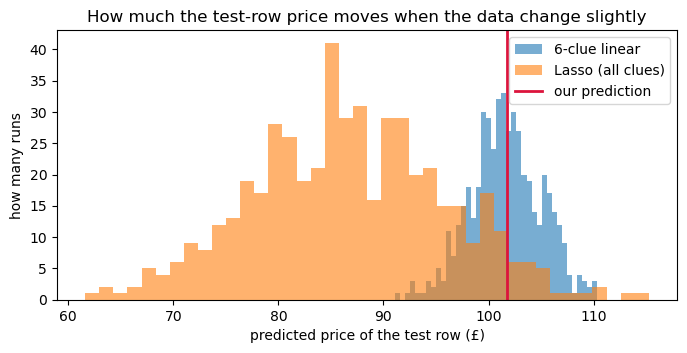

In [61]:
plt.figure(figsize=(8, 3.5))
plt.hist(boot_6clues, bins=40, alpha=0.6, label="6-clue linear")
plt.hist(boot_lasso, bins=40, alpha=0.6, label="Lasso (all clues)")
plt.axvline(prediction, color="crimson", linewidth=2, label="our prediction")
plt.xlabel("predicted price of the test row (£)"); plt.ylabel("how many runs")
plt.legend(); plt.title("How much the test-row price moves when the data change slightly")
plt.show()

**What this shows**

* The 6-clue model is fairly stable around £100, but the **Lasso disagrees with it by about £15** and is spread much more widely. Which one is right depends on which clues are truly real, and 140 rows can't fully settle that.
* Together with Step 4.3, a fair summary is: **best guess in the high £90s, but anything from about £80 to £115 is realistic.**

So the honest uncertainty for this row is about **£15**, roughly **three times** the CV RMSE. Quoting ±£5 would be badly overconfident.

> **✅ Checkpoint.** CV RMSE ≈ £5 is for normal rows. For this extreme row, the real uncertainty is ≈ £15.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: The central estimate

We don't fully trust any single model, so we ask three credible ones and take the **average**, like asking three experts and taking the middle view:

| Model | Why it's included |
|---|---|
| 6-clue linear regression | Our main model |
| 7-clue linear regression (adds x59) | x59 was kept 97% of the time but barely improved the error, so we're not sure about it. This is the "with x59" opinion. |
| Lasso | Picks its own clues; a different way of looking at the data |

The 7-clue model uses plain linear regression for the same reason as the main model: once the clues are chosen, it doesn't shrink the weights.

In [62]:
pred_7 = LinearRegression().fit(X[order[:7]], y).predict(X_test[order[:7]])[0]   # first 7 clues in the list
pred_lasso = float(searches["Lasso"].predict(X_test)[0])

centre = np.mean([prediction, pred_7, pred_lasso])
print(f"6-clue model: £{prediction:.2f}")
print(f"7-clue model: £{pred_7:.2f}")
print(f"Lasso:        £{pred_lasso:.2f}")
print(f"Central estimate (average): £{centre:.2f}")

6-clue model: £101.72
7-clue model: £106.82
Lasso:        £88.56
Central estimate (average): £99.03


### Step 7.2: The quote

Same formula as notebook 1: **bid = centre − h** and **ask = centre + h**. But here **h** comes from the honest uncertainty (about £15), **not** from the CV RMSE.

In [63]:
h = 15.0      # honest uncertainty for this extreme row (Part 6), not the CV RMSE of about £5

bid = round(centre - h, 2)
ask = round(centre + h, 2)
print(f"Quote:  bid £{bid:.2f}   ask £{ask:.2f}   (spread £{ask - bid:.2f})")

Quote:  bid £84.03   ask £114.03   (spread £30.00)


This spread is wide on purpose. **We do not want to be the market maker on stock 2.** Many teams will quote ±£5 around a single model's answer, and one of them will win the seat. We'd rather trade against them.

### Step 7.3: The trading plan

When the market maker's bid and ask appear, compare them with our range of about **£80 to £115**:

| Market maker's prices | What we do | Size |
|---|---|---|
| **Ask below about £80** | **Buy.** Even the low end of our range is above its ask. | Big |
| **Bid above about £115** | **Sell.** Even the high end of our range is below its bid. | Big |
| Ask between £80 and our centre | Buy (our centre is above its ask), but the edge is uncertain. | Small to medium |
| Bid between our centre and £115 | Sell (our centre is below its bid), but the edge is uncertain. | Small to medium |
| Our centre is between its bid and ask | No clear edge. | Minimum 10 shares, on the side our centre leans towards |

**Likely scenario:** teams using plain linear regression (about £66) or tree models (about £75–80) will centre too low. If one of them becomes market maker, **buying** is probably the edge.

> **✅ Final checkpoint.** Prediction in the high £90s, honest uncertainty about ±£15, a wide quote so we don't become market maker, and clear rules for when to trade big.